# Fine matched-L2 sweep: fully solved logistic fits

Both auxiliary and posterior-input fits minimize the **same** weighted mean logistic
loss plus $\lambda\|\beta\|_2^2$, with the **same strength**, no intercept, and the
same coefficient solution reused in both stages. This is separate from early stopping.
The 35 strengths are eight per decade from $10^{-8}$ to $10^{-4}$, plus
$3\times10^{-4}$ and $10^{-3}$. Coefficients are solved by damped Newton until the
maximum gradient magnitude is at most $10^{-10}$ and the strong-convexity
objective-gap bound $\|\nabla f\|^2/(4\lambda)$ is at most $10^{-8}$.
Failure to meet these criteria raises an error; a finite safety budget is not treated
as a converged fit. The solver was tested against an independent BFGS solution.

All other choices are explicit and unchanged: centered/whitened 110 predictors,
1,692 observations, no intercept, $\Delta=1$, equal prior odds for zero/one change,
uniform location over the 61 admissible distinct-age splits, rho start $I_2$,
damping 0.25, and 1, 3, 10, 30 rho updates. This makes **140 primary comparisons**.
State calculations initially use 256 Sobol draws/seed 42 and at most 60 evaluations.
The four closest curves and two highest-count-probability curves within 0.10 TV of
the best are checked with 512 draws/seed 42 and 1,024 draws/seed 123, at most 100
state evaluations, and 160-node Gaussian quadrature. No P(1)>0.5 cutoff is imposed.

**Full solve refers only to coefficient optimization.** Rho estimation remains a
finite-update heuristic, and the existing approximately unpenalized state equations
are used with the weakly penalized fits. Those approximation/model limitations are
not removed by accurate coefficient solves. Outcome-guided comparison with the
archived curve remains exploratory, not independently calibrated model selection.


In [1]:
"""Fine matched-L2 full coefficient solves; separate from early stopping."""
from tools.myocardial_finite_iteration_exploration import *
from tools.myocardial_exact_no_intercept import score as matched_score


def penalty_grid():
    return np.r_[np.logspace(-8,-4,33),3e-4,1e-3]


def solve_logistic_l2(X,y,w,strength):
    """Damped Newton to stationarity, not a chosen finite fitting budget.

    Objective = weighted mean logistic loss + strength * ||beta||^2.
    The strong-convexity gap bound ||gradient||^2/(4*strength) is recorded.
    A safety limit raises an error rather than returning an early-stopped fit.
    """
    if not np.isfinite(strength) or strength<=0:raise ValueError('positive finite L2 strength required')
    X=np.asarray(X,float);y=np.asarray(y,float);w=np.asarray(w,float)
    if not np.isfinite(w).all() or np.any(w<0) or w.sum()<=0:raise ValueError('invalid sample weights')
    wn=w/w.sum();beta=np.zeros(X.shape[1]);eye=np.eye(X.shape[1])
    def value(b):
        z=X@b
        return float(wn@(np.logaddexp(0,z)-y*z)+strength*(b@b))
    for it in range(101):
        z=X@beta;prob=expit(z);grad=X.T@(wn*(prob-y))+2*strength*beta
        kkt=float(np.max(abs(grad)));gap=float(grad@grad/(4*strength))
        if kkt<=1e-10 and gap<=1e-8:
            return dict(coef=beta,kkt=kkt,gap_bound=gap,iterations=it,objective=value(beta),success=True)
        if it==100:break
        H=X.T@((wn*prob*(1-prob))[:,None]*X)+2*strength*eye
        direction=np.linalg.solve(H,grad);decrease=float(grad@direction);old=value(beta);step=1.
        for backtrack in range(60):
            candidate=beta-step*direction
            if value(candidate)<=old-1e-4*step*decrease+1e-15:
                beta=candidate;break
            step*=.5
        else:raise RuntimeError('Full L2 solve line search failed')
    raise RuntimeError(f'Full L2 solve failed stationarity: KKT={kkt}, gap={gap}')


def full_fit(X,y,phi,strength):
    fits=[solve_logistic_l2(X,y,w,strength) for w in phi]
    B=np.column_stack([f['coef'] for f in fits]);theta=X@B
    V,b=empirical_adjustment(theta,y,phi,len(y)/X.shape[1],loss='logistic')
    return dict(coef=B,theta=theta,V=V,b=b,penalty='l2',strength=float(strength),
        checks=[{k:v for k,v in f.items() if k!='coef'} for f in fits])


def prepare_full(strength,setting,X,y,root):
    name=f'l2full_{strength:.12g}';path=root/('aux_'+name+'.pkl')
    if path.exists():return pickle.load(path.open('rb'))
    fit=full_fit(X,y,setting['phi'],strength)
    e,psi=pilot(fit['theta'],y,setting['eta'],'logistic');S=fit['V'].T@fit['V']/len(y)
    import WERM.myocardial_approximate as implementation
    old=implementation.logistic_prox;implementation.logistic_prox=logistic_prox_fast
    try:
        scenarios=[dict(r,auxiliary=name,pilot=e,loss='logistic')
            for r in rho_path(S,setting['phi'],psi,len(y)/X.shape[1],'logistic')]
    finally:implementation.logistic_prox=old
    result=(name,fit,scenarios);atomic_save(path,result)
    print('Full matched L2 fit and rho path ready:',strength,flush=True);return result


def score_full(rec,states,fit,setting,X,y,ages,reference,root,tag):
    path=root/(rec['label']+'_'+tag+'_score.pkl')
    if path.exists():return pickle.load(path.open('rb'))
    result=matched_score(rec,states,fit,setting,X,y,ages,reference,tag)
    result.update(label=rec['label']+'_'+tag,tag=tag,ages=ages[setting['eta'][1:]],
        posterior_fit=rec['scenario']['auxiliary'],group='fully_solved_matched_L2',
        Delta=1,rho_updates=rec['scenario']['iteration'],auxiliary=rec['scenario']['auxiliary'],
        auxiliary_strength=fit['strength'],posterior_strength=fit['strength'],
        gap_bound_max=max(c['gap_bound'] for c in fit['checks']),
        actual_fit_iterations_max=max(c['iterations'] for c in fit['checks']))
    atomic_save(path,result);return result


def run_full_matched(base):
    X,y,ages,locations=load_data();reference_map=reference_distribution()
    reference=np.array([reference_map[a] for a in ages[locations]])
    setting=pickle.load((SOURCE/'fits_delta1.pkl').open('rb'))
    digest=hashlib.sha256(Path('tools/myocardial_matched_l2_fine.py').read_bytes()).hexdigest()[:12]
    root=base/('matched_l2_full_'+digest);root.mkdir(exist_ok=True)
    print('Fine full-solve matched L2 directory:',root,flush=True)
    with parallel_config(backend='loky',inner_max_num_threads=1):
        prepared=Parallel(n_jobs=35)(delayed(prepare_full)(v,setting,X,y,root) for v in penalty_grid())
        tasks=[(name,fit,r) for name,fit,scenarios in prepared for r in scenarios]
        records=Parallel(n_jobs=36)(delayed(evaluate_refined)(dict(setting,fits={}),r,X,y,ages,root,8,60) for name,fit,r in tasks)
        results=Parallel(n_jobs=36)(delayed(score_full)(rec,rec['states'],fit,setting,X,y,ages,reference,root,'primary')
                                    for rec,(name,fit,r) in zip(records,tasks))
    def table(rows):return pd.DataFrame([{k:v for k,v in r.items() if k not in ('conditional','ages')} for r in rows])
    summary=table(results);summary.to_csv(root/'summary.csv',index=False)
    # Shape first, with count probability a trade-off, never a hard filter.
    closest=summary.sort_values('TV_to_reference').head(4)
    nearby=summary[summary.TV_to_reference<=summary.TV_to_reference.min()+.1].sort_values('P_1',ascending=False).head(2)
    selected=pd.concat([closest,nearby]).drop_duplicates('case')
    selected.to_csv(root/'selected_for_validation.csv',index=False)
    case_map={r['label']:(r,t[1]) for r,t in zip(records,tasks)}
    jobs=[(case_map[c],power,seed) for c in selected.case for power,seed in ((9,42),(10,123))]
    with parallel_config(backend='loky',inner_max_num_threads=1):
        states=Parallel(n_jobs=len(jobs))(delayed(refined_states)(r,setting,len(y),X.shape[1],root,power,seed)
                                        for (r,fit),power,seed in jobs)
        checks=Parallel(n_jobs=36)(delayed(score_full)(r,state,fit,setting,X,y,ages,reference,root,f'q{power}_seed{seed}')
                                  for ((r,fit),power,seed),state in zip(jobs,states))
    validation=table(checks);validation.to_csv(root/'validation.csv',index=False)
    ranked=validation.groupby(['case','posterior_fit','group','strength'],as_index=False).agg(
        P1_min=('P_1','min'),P1_max=('P_1','max'),mean_TV=('TV_to_reference','mean'),max_TV=('TV_to_reference','max'),
        mass_above55_min=('mass_above55','min'),peak_min=('peak_age','min'),peak_max=('peak_age','max'),
        moment_residual=('moment_residual','max'),fit_kkt_max=('fit_kkt_max','max'),gap_bound_max=('gap_bound_max','max')).sort_values('mean_TV')
    ranked.to_csv(root/'ranked.csv',index=False)
    print('FULL-SOLVE MATCHED L2 COMPLETE:',len(summary),'primary comparisons.',flush=True)
    print(ranked.to_string(index=False),flush=True);return root




/scratch/ga442/gab-code-env/papers/WeightedERM-reference/.venv-phase1/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
base=Path('results/myocardial_finite_iteration_443c17cf2df6')
matched_root=run_full_matched(base)
full_summary=pd.read_csv(matched_root/'summary.csv')
full_validation=pd.read_csv(matched_root/'validation.csv')
full_ranked=pd.read_csv(matched_root/'ranked.csv')
display(full_ranked)


Fine full-solve matched L2 directory: results/myocardial_finite_iteration_443c17cf2df6/matched_l2_full_affdef22fb6c


Full matched L2 fit and rho path ready: 4.216965034285822e-05


Full matched L2 fit and rho path ready: 7.498942093324559e-05


Full matched L2 fit and rho path ready: 2.3713737056616554e-05


Full matched L2 fit and rho path ready: 9.999999999999999e-06


Full matched L2 fit and rho path ready: 3.1622776601683795e-05


... (165 outputs left out)

Numerical validation complete: d1_l2full_7.49894209332e-05_it30_q8_b60 10 123


FULL-SOLVE MATCHED L2 COMPLETE: 140 primary comparisons.


                                   case            posterior_fit                   group  strength   P1_min   P1_max  mean_TV   max_TV  mass_above55_min  peak_min  peak_max  moment_residual  fit_kkt_max  gap_bound_max
d1_l2full_4.21696503429e-05_it30_q8_b60 l2full_4.21696503429e-05 fully_solved_matched_L2  0.000042 0.511128 0.520916 0.648567 0.652651          0.596253      66.0      68.0         0.284075 2.259364e-12   1.511175e-19
 d1_l2full_5.6234132519e-05_it30_q8_b60  l2full_5.6234132519e-05 fully_solved_matched_L2  0.000056 0.512744 0.524969 0.651158 0.656271          0.594404      66.0      67.0         0.367151 3.468395e-14   2.686072e-23
d1_l2full_7.49894209332e-05_it30_q8_b60 l2full_7.49894209332e-05 fully_solved_matched_L2  0.000075 0.513934 0.528315 0.653160 0.659173          0.592811      66.0      66.0         0.437351 2.573896e-16   1.109694e-27
           d1_l2full_0.0001_it30_q8_b60            l2full_0.0001 fully_solved_matched_L2  0.000100 0.514800 0.530982 0.654661 0.

,case,posterior_fit,group,strength,P1_min,P1_max,mean_TV,max_TV,mass_above55_min,peak_min,peak_max,moment_residual,fit_kkt_max,gap_bound_max
0,d1_l2full_4.21696503429e-05_it30_q8_b60,l2full_4.21696503429e-05,fully_solved_matched_L2,0.000042,0.511128,0.520916,0.648567,0.652651,0.596253,66.0,68.0,0.284075,2.259364e-12,1.511175e-19
1,d1_l2full_5.6234132519e-05_it30_q8_b60,l2full_5.6234132519e-05,fully_solved_matched_L2,0.000056,0.512744,0.524969,0.651158,0.656271,0.594404,66.0,67.0,0.367151,3.468395e-14,2.686072e-23
2,d1_l2full_7.49894209332e-05_it30_q8_b60,l2full_7.49894209332e-05,fully_solved_matched_L2,0.000075,0.513934,0.528315,0.653160,0.659173,0.592811,66.0,66.0,0.437351,2.573896e-16,1.109694e-27
3,d1_l2full_0.0001_it30_q8_b60,l2full_0.0001,fully_solved_matched_L2,0.000100,0.514800,0.530982,0.654661,0.661420,0.591512,65.0,66.0,0.493835,3.281310e-11,1.331241e-17
4,d1_l2full_0.0003_it30_q8_b60,l2full_0.0003,fully_solved_matched_L2,0.000300,0.516320,0.536090,0.657259,0.665487,0.588921,64.0,66.0,0.600446,3.355606e-17,4.769203e-30
5,d1_l2full_0.001_it30_q8_b60,l2full_0.001,fully_solved_matched_L2,0.001000,0.516698,0.537052,0.657694,0.666157,0.588282,64.0,66.0,0.616852,7.511060e-14,7.034816e-24


All matched strengths: primary numerical accuracy


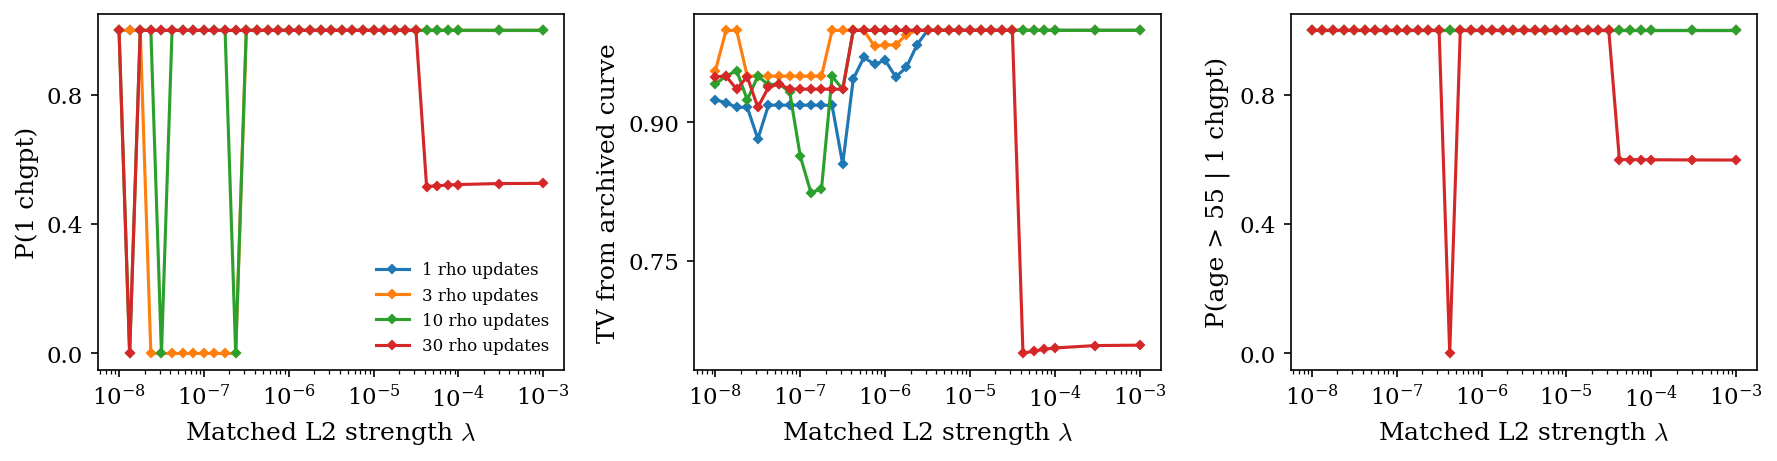

Both stages: L2=4.21697e-05; d1_l2full_4.21696503429e-05_it30_q8_b60; P(1)=0.5111–0.5209; mean TV=0.6486


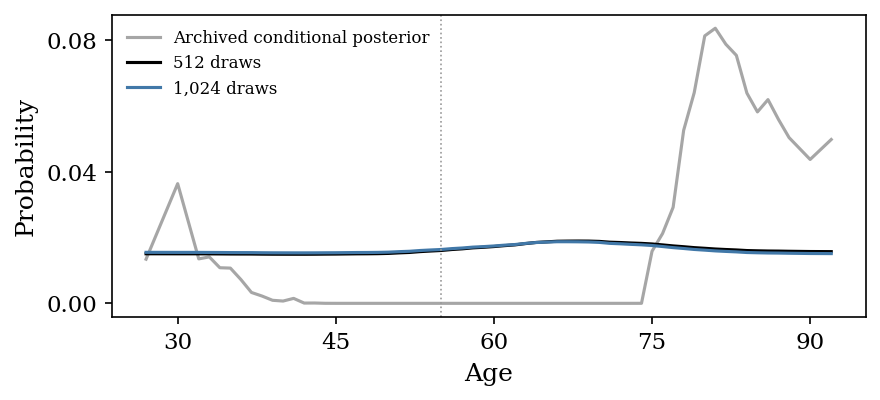

Both stages: L2=5.62341e-05; d1_l2full_5.6234132519e-05_it30_q8_b60; P(1)=0.5127–0.525; mean TV=0.6512


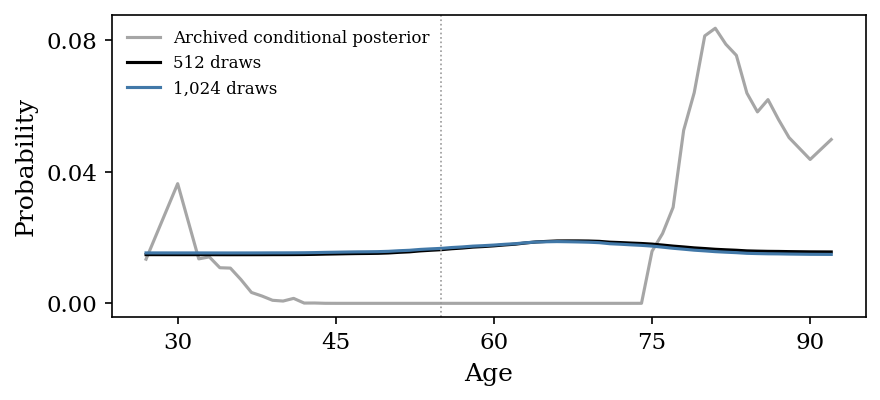

Both stages: L2=7.49894e-05; d1_l2full_7.49894209332e-05_it30_q8_b60; P(1)=0.5139–0.5283; mean TV=0.6532


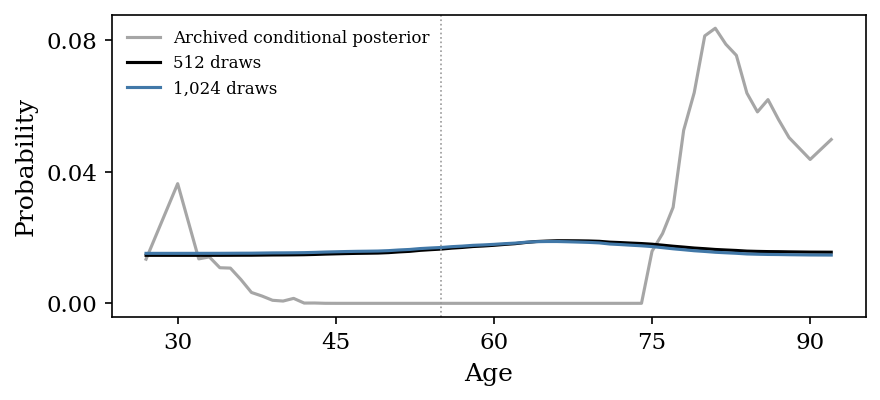

Both stages: L2=0.0001; d1_l2full_0.0001_it30_q8_b60; P(1)=0.5148–0.531; mean TV=0.6547


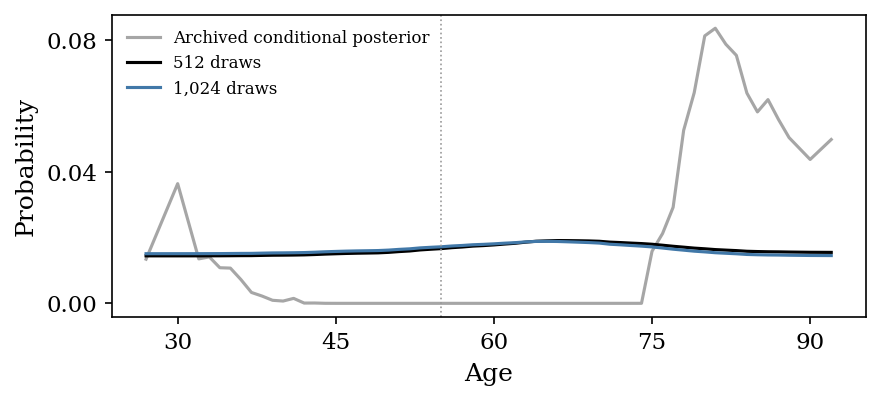

Both stages: L2=0.0003; d1_l2full_0.0003_it30_q8_b60; P(1)=0.5163–0.5361; mean TV=0.6573


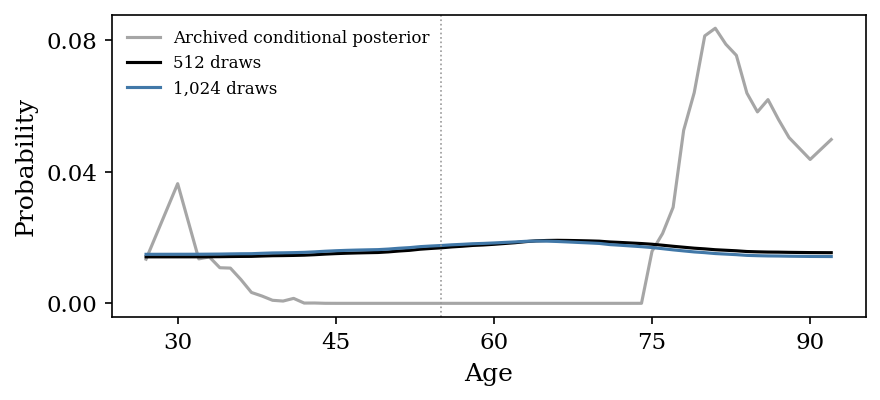

Both stages: L2=0.001; d1_l2full_0.001_it30_q8_b60; P(1)=0.5167–0.5371; mean TV=0.6577


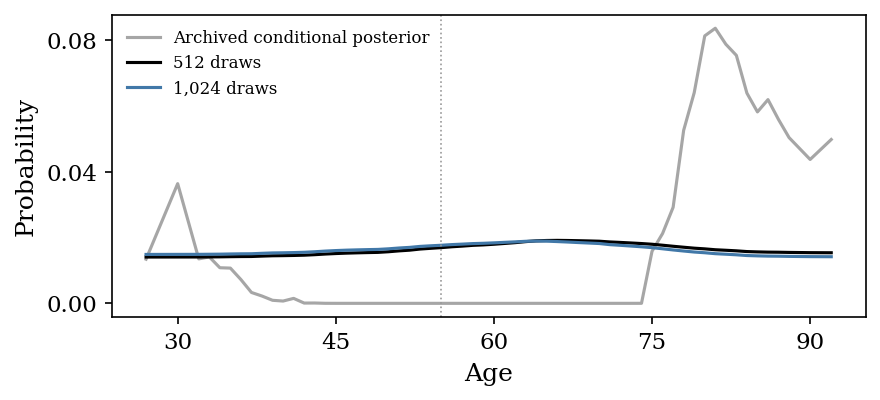

,case,penalty,strength,seed_label,P_1,mass_above55,peak_age,TV_to_reference,moment_residual,FP_residual_max,...,tag,posterior_fit,group,Delta,rho_updates,auxiliary,auxiliary_strength,posterior_strength,gap_bound_max,actual_fit_iterations_max
0,d1_l2full_4.21696503429e-05_it30_q8_b60,l2,0.000042,q9_seed42,0.511128,0.606726,68.0,0.644483,0.284075,1.147679e-09,...,q9_seed42,l2full_4.21696503429e-05,fully_solved_matched_L2,1,30,l2full_4.21696503429e-05,0.000042,0.000042,1.511175e-19,4
1,d1_l2full_4.21696503429e-05_it30_q8_b60,l2,0.000042,q10_seed123,0.520916,0.596253,66.0,0.652651,0.284075,1.188796e-09,...,q10_seed123,l2full_4.21696503429e-05,fully_solved_matched_L2,1,30,l2full_4.21696503429e-05,0.000042,0.000042,1.511175e-19,4
2,d1_l2full_5.6234132519e-05_it30_q8_b60,l2,0.000056,q9_seed42,0.512744,0.607587,67.0,0.646044,0.367151,1.147679e-09,...,q9_seed42,l2full_5.6234132519e-05,fully_solved_matched_L2,1,30,l2full_5.6234132519e-05,0.000056,0.000056,2.686072e-23,4
3,d1_l2full_5.6234132519e-05_it30_q8_b60,l2,0.000056,q10_seed123,0.524969,0.594404,66.0,0.656271,0.367151,1.188796e-09,...,q10_seed123,l2full_5.6234132519e-05,fully_solved_matched_L2,1,30,l2full_5.6234132519e-05,0.000056,0.000056,2.686072e-23,4
4,d1_l2full_7.49894209332e-05_it30_q8_b60,l2,0.000075,q9_seed42,0.513934,0.608361,66.0,0.647146,0.437351,1.147679e-09,...,q9_seed42,l2full_7.49894209332e-05,fully_solved_matched_L2,1,30,l2full_7.49894209332e-05,0.000075,0.000075,1.109694e-27,4
5,d1_l2full_7.49894209332e-05_it30_q8_b60,l2,0.000075,q10_seed123,0.528315,0.592811,66.0,0.659173,0.437351,1.188796e-09,...,q10_seed123,l2full_7.49894209332e-05,fully_solved_matched_L2,1,30,l2full_7.49894209332e-05,0.000075,0.000075,1.109694e-27,4
6,d1_l2full_0.0001_it30_q8_b60,l2,0.000100,q9_seed42,0.514800,0.609021,66.0,0.647903,0.493835,1.147679e-09,...,q9_seed42,l2full_0.0001,fully_solved_matched_L2,1,30,l2full_0.0001,0.000100,0.000100,1.331241e-17,3
7,d1_l2full_0.0001_it30_q8_b60,l2,0.000100,q10_seed123,0.530982,0.591512,65.0,0.661420,0.493835,1.188796e-09,...,q10_seed123,l2full_0.0001,fully_solved_matched_L2,1,30,l2full_0.0001,0.000100,0.000100,1.331241e-17,3
8,d1_l2full_0.001_it30_q8_b60,l2,0.001000,q9_seed42,0.516698,0.610275,66.0,0.649232,0.616852,1.147679e-09,...,q9_seed42,l2full_0.001,fully_solved_matched_L2,1,30,l2full_0.001,0.001000,0.001000,7.034816e-24,2
9,d1_l2full_0.001_it30_q8_b60,l2,0.001000,q10_seed123,0.537052,0.588282,64.0,0.666157,0.616852,1.188796e-09,...,q10_seed123,l2full_0.001,fully_solved_matched_L2,1,30,l2full_0.001,0.001000,0.001000,7.034816e-24,2


In [3]:
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
plt.rcParams.update({'font.family':'serif','mathtext.fontset':'cm','font.size':11,
                     'axes.labelsize':12,'figure.dpi':150})
print('All matched strengths: primary numerical accuracy')
fig,axes=plt.subplots(1,3,figsize=(12,3.2))
for updates,data in full_summary.groupby('rho_updates'):
    data=data.sort_values('strength')
    for ax,key in zip(axes,('P_1','TV_to_reference','mass_above55')):
        ax.semilogx(data.strength,data[key],'-D',ms=3,label=f'{updates} rho updates')
for ax,label in zip(axes,('P(1 chgpt)','TV from archived curve','P(age > 55 | 1 chgpt)')):
    ax.set_xlabel(r'Matched L2 strength $\lambda$');ax.set_ylabel(label)
    ax.yaxis.set_major_locator(MaxNLocator(3))
axes[0].legend(frameon=False,fontsize=8);fig.tight_layout();plt.show()
reference=reference_distribution();a=np.array(sorted(reference));p=np.array([reference[x] for x in a])
for row in full_ranked.itertuples():
    print(f'Both stages: L2={row.strength:g}; {row.case}; '
          f'P(1)={row.P1_min:.4g}–{row.P1_max:.4g}; mean TV={row.mean_TV:.4g}')
    fig,ax=plt.subplots(figsize=(6,2.8))
    ax.plot(a,p,color='0.65',label='Archived conditional posterior')
    for tag,color,label in [('q9_seed42','black','512 draws'),('q10_seed123','#4178a8','1,024 draws')]:
        rec=pickle.load((matched_root/(row.case+'_'+tag+'_score.pkl')).open('rb'))
        ax.plot(rec['ages'],rec['conditional'],color=color,label=label)
    ax.axvline(55,color='0.6',ls=':',lw=.8);ax.set_xlabel('Age');ax.set_ylabel('Probability')
    ax.yaxis.set_major_locator(MaxNLocator(3));ax.xaxis.set_major_locator(MaxNLocator(5,integer=True))
    ax.legend(frameon=False,fontsize=8);fig.tight_layout();plt.show()
display(full_validation)


In [4]:
print('Combined numerically checked candidates: early stopping, initializations, and full matched L2')
earlier=pd.read_csv(base/'combined_checked_candidates.csv')
new=[]
for row in full_ranked.to_dict('records'):
    recs=[pickle.load((matched_root/(row['case']+'_'+tag+'_score.pkl')).open('rb'))
          for tag in ('q9_seed42','q10_seed123')]
    row.update(stage='fully_solved_matched_L2',Delta=1,initialization='identity',
        auxiliary=recs[0]['auxiliary'],rho_updates=recs[0]['rho_updates'],
        numerical_curve_TV=.5*np.abs(recs[0]['conditional']-recs[1]['conditional']).sum())
    new.append(row)
all_candidates=pd.concat([earlier,pd.DataFrame(new)],ignore_index=True).sort_values('mean_TV')
all_candidates.to_csv(base/'combined_with_full_l2.csv',index=False)
display(all_candidates)
print('Best curve matches in each class (not a statistical acceptance rule):')
display(all_candidates.groupby('group',sort=False).head(3))
print('Ranges across numerical checks are not confidence intervals. Small TV does not establish calibration.')


Combined numerically checked candidates: early stopping, initializations, and full matched L2


,case,posterior_fit,group,P1_min,P1_max,mean_TV,max_TV,mass_above55_min,peak_min,peak_max,...,auxiliary_budget,posterior_budget,rho_updates,numerical_curve_TV,min_interval90_width,max_interval90_width,initialization,strength,fit_kkt_max,gap_bound_max
0,d5_least_squares_it24_q8_b60,fista16,least_squares,0.260890,0.265568,0.169467,0.170571,9.002295e-01,81.0,81.0,...,0.0,16.0,24,3.130377e-02,54.0,54.0,NaN,NaN,NaN,NaN
1,d2_least_squares_it20_q8_b60,fista12,least_squares,0.430037,0.437390,0.175996,0.184404,9.346447e-01,80.0,80.0,...,0.0,12.0,20,2.424608e-02,16.0,57.0,NaN,NaN,NaN,NaN
2,d2_least_squares_it20_q8_b60,fista16,least_squares,0.463740,0.482719,0.216686,0.227457,9.583956e-01,81.0,81.0,...,0.0,16.0,20,3.062949e-02,10.0,13.0,NaN,NaN,NaN,NaN
3,d5_least_squares_it20_q8_b60,lbfgs5,least_squares,0.205679,0.214709,0.248653,0.248909,9.009691e-01,84.0,84.0,...,0.0,5.0,20,6.232307e-02,11.0,55.0,NaN,NaN,NaN,NaN
4,d10_least_squares_it20_q8_b60,lbfgs5,least_squares,0.201833,0.205649,0.266246,0.270968,9.476632e-01,83.0,83.0,...,0.0,5.0,20,3.427498e-02,10.0,50.0,NaN,NaN,NaN,NaN
5,d2_least_squares_it16_q8_b60,lbfgs5,least_squares,0.305700,0.316399,0.305304,0.321317,9.217486e-01,84.0,84.0,...,0.0,5.0,16,6.591722e-02,10.0,58.0,NaN,NaN,NaN,NaN
6,d1_least_squares_it30_q8_b60,early10,least_squares,0.401266,0.406337,0.494824,0.499693,6.327934e-01,27.0,78.0,...,0.0,10.0,30,1.873924e-02,58.0,58.0,NaN,NaN,NaN,NaN
7,d1_least_squares_it30_q8_b60,early3,least_squares,0.489498,0.495491,0.618732,0.622118,6.159525e-01,72.0,72.0,...,0.0,3.0,30,1.101070e-02,56.0,56.0,NaN,NaN,NaN,NaN
8,d1_least_squares_it30_q8_b60,early1,least_squares,0.511236,0.518780,0.639888,0.642866,6.193926e-01,69.0,69.0,...,0.0,1.0,30,8.183063e-03,54.0,54.0,NaN,NaN,NaN,NaN
37,d1_l2full_4.21696503429e-05_it30_q8_b60,l2full_4.21696503429e-05,fully_solved_matched_L2,0.511128,0.520916,0.648567,0.652651,5.962531e-01,66.0,68.0,...,NaN,NaN,30,1.192095e-02,NaN,NaN,identity,0.000042,2.259364e-12,1.511175e-19


Best curve matches in each class (not a statistical acceptance rule):


,case,posterior_fit,group,P1_min,P1_max,mean_TV,max_TV,mass_above55_min,peak_min,peak_max,...,auxiliary_budget,posterior_budget,rho_updates,numerical_curve_TV,min_interval90_width,max_interval90_width,initialization,strength,fit_kkt_max,gap_bound_max
0,d5_least_squares_it24_q8_b60,fista16,least_squares,0.260890,0.265568,0.169467,0.170571,9.002295e-01,81.0,81.0,...,0.0,16.0,24,3.130377e-02,54.0,54.0,NaN,NaN,NaN,NaN
1,d2_least_squares_it20_q8_b60,fista12,least_squares,0.430037,0.437390,0.175996,0.184404,9.346447e-01,80.0,80.0,...,0.0,12.0,20,2.424608e-02,16.0,57.0,NaN,NaN,NaN,NaN
2,d2_least_squares_it20_q8_b60,fista16,least_squares,0.463740,0.482719,0.216686,0.227457,9.583956e-01,81.0,81.0,...,0.0,16.0,20,3.062949e-02,10.0,13.0,NaN,NaN,NaN,NaN
37,d1_l2full_4.21696503429e-05_it30_q8_b60,l2full_4.21696503429e-05,fully_solved_matched_L2,0.511128,0.520916,0.648567,0.652651,5.962531e-01,66.0,68.0,...,NaN,NaN,30,1.192095e-02,NaN,NaN,identity,0.000042,2.259364e-12,1.511175e-19
38,d1_l2full_5.6234132519e-05_it30_q8_b60,l2full_5.6234132519e-05,fully_solved_matched_L2,0.512744,0.524969,0.651158,0.656271,5.944039e-01,66.0,67.0,...,NaN,NaN,30,1.507890e-02,NaN,NaN,identity,0.000056,3.468395e-14,2.686072e-23
39,d1_l2full_7.49894209332e-05_it30_q8_b60,l2full_7.49894209332e-05,fully_solved_matched_L2,0.513934,0.528315,0.653160,0.659173,5.928107e-01,66.0,66.0,...,NaN,NaN,30,1.784189e-02,NaN,NaN,identity,0.000075,2.573896e-16,1.109694e-27
9,d1_early30_init_scale10_corr0_it3_q8_b60,early30,logistic_matched,1.000000,1.000000,0.877078,0.916425,1.000000e+00,81.0,81.0,...,30.0,30.0,3,4.620850e-01,0.0,1.0,scale10_corr0,NaN,NaN,NaN
10,d1_early30_it3_q8_b60,early30,logistic_matched,1.000000,1.000000,0.877085,0.916439,1.000000e+00,81.0,81.0,...,30.0,30.0,3,2.725689e-01,0.0,1.0,NaN,NaN,NaN,NaN
11,d1_early30_init_scale1_corr0_it3_q8_b60,early30,logistic_matched,1.000000,1.000000,0.877085,0.916439,1.000000e+00,81.0,81.0,...,30.0,30.0,3,2.725689e-01,0.0,1.0,scale1_corr0,NaN,NaN,NaN
14,d1_early100_it30_q8_b60,early1,logistic_different_budgets,1.000000,1.000000,0.885094,0.885094,1.330201e-71,35.0,41.0,...,100.0,1.0,30,3.918490e-02,12.0,12.0,NaN,NaN,NaN,NaN


Ranges across numerical checks are not confidence intervals. Small TV does not establish calibration.


## Earlier promising alternatives (retained in the final comparison)

| Earlier fit setup | Intercept | P(1) across numerical checks | Main trade-off |
|---|---|---|---|
| LS auxiliary; logistic L1 1e-4 posterior fit; 30 rho updates | No | 0.402–0.453 | Mode 79; original-like but count probability below 0.5 |
| LS auxiliary; logistic L2 1e-6 posterior fit; 3 rho updates | No | 0.99988–0.99998 | Mode 87; too concentrated/late relative to reference |
| LS auxiliary; logistic L2 1e-5 posterior fit; 30 rho updates | No | 0.481–0.484 | Mode 75; diffuse |
| Logistic L1 1e-4 auxiliary; logistic L2 1.5e-6 posterior fit; 30 updates | Yes | 0.718–0.747 | Mode 81; mean reference TV 0.291; mismatched penalties |
| Logistic L1 1e-4 auxiliary; logistic L1 1e-5 posterior fit; 30 updates | Yes | 0.654–0.680 | Mode 81; mean reference TV 0.367; mismatched strengths |

These historical candidates remain exploratory and are not relabeled as satisfying
the no-intercept or exactly matched-penalty preferences when they do not.
